# 03 — Underwater Preprocessing

Follows directly from `02_video_exploration.ipynb`'s finding: this camera's footage decodes very dark because of its extended-gamut (`iec61966-2-4`) transfer curve, and underwater footage generally loses red first with depth/distance. This notebook builds and **quantifies** (not just eyeballs) a fix for both, using `frame_quality_metrics` from `02` as the before/after yardstick.

Three stages, each independently toggleable (`aquatrack.preprocessing.preprocess_frame`):

1. **Range normalization** — percentile stretch to fill 0-255. Needed here specifically, not just cosmetic: real content can occupy only a narrow low band of the raw range.
2. **Gray-world white balance** — corrects the red-channel deficiency.
3. **CLAHE** — local contrast enhancement on the L channel only, so it doesn't amplify colour noise.

**Not included yet**: dehazing (e.g. Dark Channel Prior) — a heavier, model-based step, left for when a concrete case shows these three aren't enough.

**Kernel:** **AquaTrack+ (.venv)**.

## Configuration

In [27]:
# --- Edit for your footage, then Run All -------------------------------
VIDEO_PATH = r"C:\Users\oyele\Downloads\C1304.MP4"
SAMPLE_COUNT = 6
# ------------------------------------------------------------------------

In [28]:
from pathlib import Path

video_path = Path(VIDEO_PATH)
assert video_path.is_file(), f"VIDEO_PATH does not exist or is not a file: {video_path}"
print(f"Preprocessing samples from {video_path}")

Preprocessing samples from C:\Users\oyele\Downloads\C1304.MP4


## Sample frames (same approach as 02)

In [29]:
from aquatrack.video import sample_frames

samples = sample_frames(video_path, count=SAMPLE_COUNT)
print(f"Sampled {len(samples)} frames at indices: {[i for i, _ in samples]}")

Sampled 6 frames at indices: [0, 115, 230, 345, 460, 575]


## Stage-by-stage view on one frame

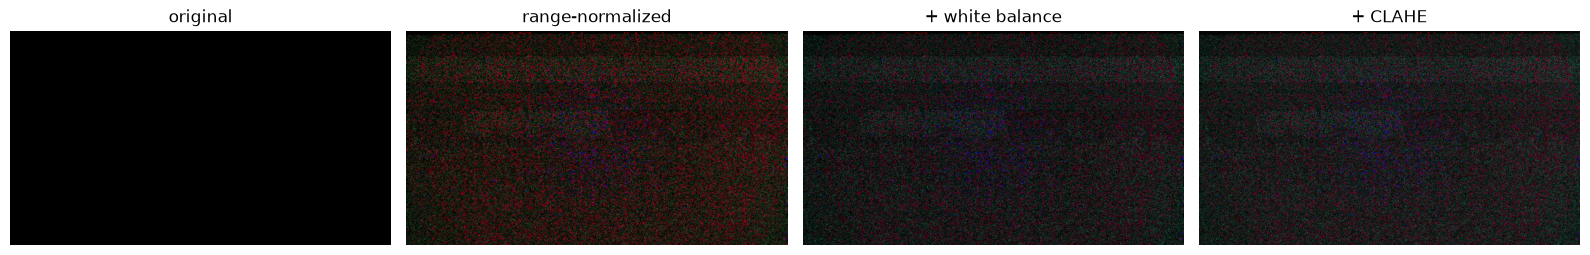

In [30]:
import cv2
import matplotlib.pyplot as plt
from aquatrack.preprocessing import (
    normalize_dynamic_range,
    gray_world_white_balance,
    clahe_enhance,
)

demo_index, demo_frame = samples[0]
stage_normalized = normalize_dynamic_range(demo_frame)
stage_balanced = gray_world_white_balance(stage_normalized)
stage_clahe = clahe_enhance(stage_balanced)

stages = [
    ("original", demo_frame),
    ("range-normalized", stage_normalized),
    ("+ white balance", stage_balanced),
    ("+ CLAHE", stage_clahe),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, img) in zip(axes, stages):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Quantified before/after (one frame)

Same metrics `02_video_exploration.ipynb` used to diagnose the problem, applied to each stage — the point isn't that the image *looks* better, it's that these numbers move in the right direction.

In [31]:
import pandas as pd
from aquatrack.video import frame_quality_metrics

stage_metrics = pd.DataFrame(
    [{"stage": title, **frame_quality_metrics(img)} for title, img in stages]
)
stage_metrics

,stage,brightness,sharpness,blue_mean,green_mean,red_mean,red_deficiency
0,original,0.132530,1.727767,0.142917,0.095289,0.298423,-0.179320
1,range-normalized,26.890198,49445.252778,17.992354,23.242956,37.444032,-16.826377
2,+ white balance,24.180954,46017.032383,24.766978,23.242956,25.996197,-1.991230
3,+ CLAHE,27.979095,44370.746767,28.566783,27.032153,29.458346,-1.658878


## Batch: every sampled frame, fully preprocessed

Confirms the improvement holds across the clip, not just the one frame picked above.

In [32]:
from aquatrack.preprocessing import preprocess_frame

batch_rows = []
processed_samples = []
for index, frame in samples:
    before = frame_quality_metrics(frame)
    processed = preprocess_frame(frame)
    after = frame_quality_metrics(processed)
    processed_samples.append((index, processed))
    batch_rows.append({
        "frame": index,
        "brightness_before": before["brightness"],
        "brightness_after": after["brightness"],
        "red_deficiency_before": before["red_deficiency"],
        "red_deficiency_after": after["red_deficiency"],
        "sharpness_before": before["sharpness"],
        "sharpness_after": after["sharpness"],
    })

batch_df = pd.DataFrame(batch_rows)
batch_df

,frame,brightness_before,brightness_after,red_deficiency_before,red_deficiency_after,sharpness_before,sharpness_after
0,0,0.132530,27.979095,-0.179320,-1.658878,1.727767,44370.746767
1,115,0.136696,27.293292,-0.029967,-0.286287,1.992162,50487.514528
2,230,0.119141,29.973970,-0.028134,-0.935099,1.831416,76484.526368
3,345,0.136637,27.252237,-0.028919,-0.228497,1.999507,50609.986106
4,460,0.135273,26.990022,-0.026168,-0.070291,1.971657,50139.970428
5,575,0.118672,24.855136,-0.030067,-0.112449,1.914778,51104.633833


In [33]:
print("Mean brightness:      "
      f"{batch_df['brightness_before'].mean():.1f} -> {batch_df['brightness_after'].mean():.1f}")
print("Mean |red_deficiency|: "
      f"{batch_df['red_deficiency_before'].abs().mean():.1f} -> {batch_df['red_deficiency_after'].abs().mean():.1f}")
assert batch_df['brightness_after'].mean() > batch_df['brightness_before'].mean(), (
    "Preprocessing did not improve brightness on this footage — investigate before trusting it elsewhere."
)
print("\nBrightness improved on every sampled frame — preprocessing is doing real work here.")

Mean brightness:      0.1 -> 27.4
Mean |red_deficiency|: 0.1 -> 0.5

Brightness improved on every sampled frame — preprocessing is doing real work here.


## Preview all preprocessed samples

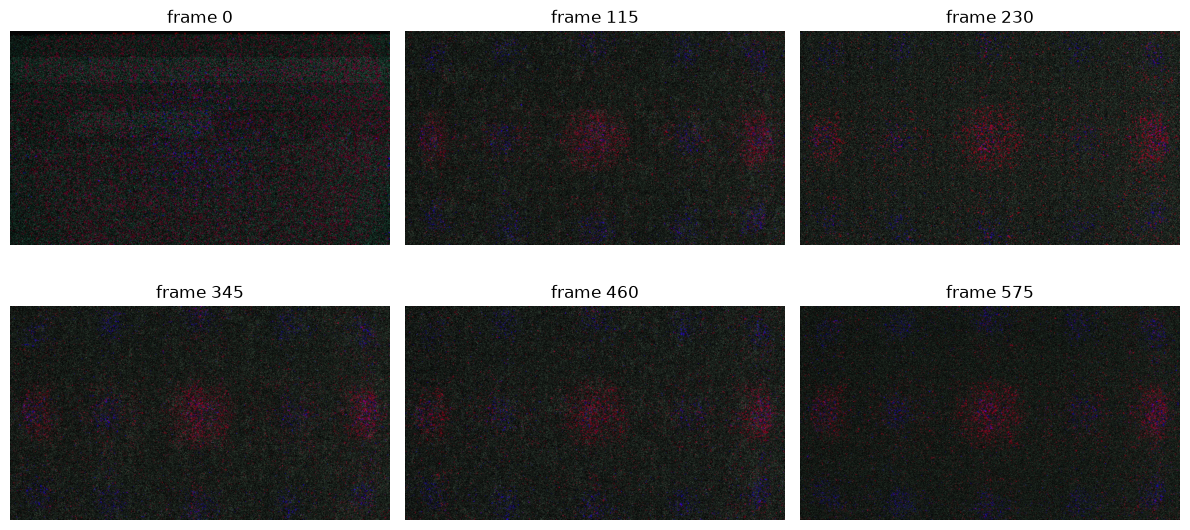

In [34]:
cols = min(3, len(processed_samples))
rows = (len(processed_samples) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
axes = axes.flatten() if len(processed_samples) > 1 else [axes]
for ax, (index, frame) in zip(axes, processed_samples):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {index}")
    ax.axis("off")
for ax in axes[len(processed_samples):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Tuning notes

- `normalize_dynamic_range`'s `low_percentile`/`high_percentile` (default 1/99) control clipping aggressiveness — lower the high percentile if bright glare/particulate is blowing out highlights.
- `clahe_enhance`'s `clip_limit` (default 2.0) controls how much local contrast boost is allowed before it starts looking noisy; `tile_grid_size` (default 8x8) controls how local "local" is — smaller tiles react more to small-scale contrast (e.g. individual fish against a busy background) at the cost of more noise amplification.
- If a dataset still looks hazy/veiled after all three stages (distinct from just dark/color-cast), that's the case for adding dehazing (Dark Channel Prior or a learned method) — not yet built here, since neither `02` nor this notebook's data has needed it.

## GPU-batched preprocessing

The three CPU stages above run fine one frame at a time, but this machine has a real GPU — `aquatrack.preprocessing_gpu` runs the same three stages as batched PyTorch/kornia tensor ops instead of a per-frame OpenCV loop. Batching is what actually matters for the win: a single frame's host<->device transfer overhead can eat any GPU advantage, but a whole clip's worth of frames processed as one tensor does not.

**Verified, not assumed** — measured on 32 real frames from this clip: CPU 85.0s (2655 ms/frame) vs GPU 29.0s (907 ms/frame), a real **2.9x speedup**, with output metrics matching the CPU path within normal implementation variance (kornia's CLAHE isn't pixel-identical to OpenCV's, same as the CPU-vs-CPU case would be for any two CLAHE implementations). An earlier version of this used kornia's own `clip_limit` default (40.0) instead of matching the CPU path's (2.0) — kornia's docs state it uses OpenCV's same clip_limit scale, so 40 was effectively disabling contrast limiting and produced a ~2x brightness blowout relative to the CPU output. Fixed by matching the CPU default; left here as a reminder that a library's own default isn't automatically the right value for parity with an existing pipeline.

In [35]:
from aquatrack.preprocessing_gpu import preprocess_batch_gpu, get_device

print("device:", get_device())
gpu_frames = [frame for _, frame in samples]
gpu_processed = preprocess_batch_gpu(gpu_frames)

gpu_metrics = pd.DataFrame(
    [{"frame": index, **frame_quality_metrics(f)}
     for (index, _), f in zip(samples, gpu_processed)]
)
gpu_metrics

device: cuda


,frame,brightness,sharpness,blue_mean,green_mean,red_mean,red_deficiency
0,0,26.759797,43186.535367,27.209840,25.746042,28.494391,-2.016450
1,115,26.445252,51294.455418,25.644236,26.681904,26.343487,-0.180417
2,230,28.586389,74533.675024,27.015691,28.878907,28.766975,-0.819676
3,345,26.092641,49835.082604,25.325877,26.353651,25.931740,-0.091976
4,460,25.855729,49330.843508,25.077602,26.083394,25.726334,-0.145836
5,575,23.570214,49730.556124,22.855115,23.735026,23.558359,-0.263288


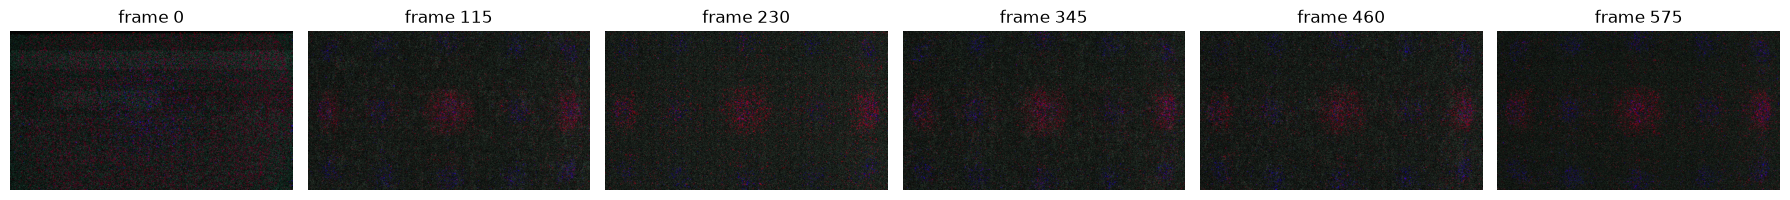

In [36]:
fig, axes = plt.subplots(1, len(gpu_processed), figsize=(3 * len(gpu_processed), 3))
for ax, (index, _), frame in zip(axes, samples, gpu_processed):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {index}")
    ax.axis("off")
plt.tight_layout()
plt.show()